In [1]:
# 02_model_building.ipynb
# Phase 7: TF-IDF features + stratified train/test split

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.5 | numpy 2.5.2


In [2]:
df = pd.read_csv("../data/processed/reviews_clean.csv")

print(df.shape)
print(df.columns.tolist())

(10254, 14)
['reviewerID', 'asin', 'reviewText', 'overall', 'unixReviewTime', 'reviewTime', 'helpful_votes', 'total_votes', 'review_date', 'sentiment', 'review_words', 'review_year', 'clean_review', 'clean_words']


In [3]:
# sanity: no missing/empty text, labels intact
print("NaN clean reviews   :", df["clean_review"].isna().sum())
print("empty clean reviews :", (df["clean_review"].astype(str).str.strip() == "").sum())
print()
print(df["sentiment"].value_counts())

NaN clean reviews   : 0
empty clean reviews : 0

sentiment
positive    9015
neutral      772
negative     467
Name: count, dtype: int64


In [4]:
X = df["clean_review"]   # the preprocessed text from Phase 6
y = df["sentiment"]      # negative / neutral / positive

print("X:", X.shape, "| y:", y.shape)

X: (10254,) | y: (10254,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # 80% train / 20% test
    random_state=42,    # reproducible - same split every run
    stratify=y          # keep the 88 / 7.5 / 4.5 class ratios in BOTH sets
)

print("train:", X_train.shape[0], "reviews")
print("test :", X_test.shape[0], "reviews")

train: 8203 reviews
test : 2051 reviews


In [6]:
# class RATIOS should be nearly identical in all three columns
pd.DataFrame({
    "full":  y.value_counts(normalize=True).round(3),
    "train": y_train.value_counts(normalize=True).round(3),
    "test":  y_test.value_counts(normalize=True).round(3),
})

,full,train,test
sentiment,,,
positive,0.879,0.879,0.879
neutral,0.075,0.075,0.076
negative,0.046,0.046,0.045


In [7]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),   # unigrams + bigrams - EDA showed "not work" vs "works great"
    min_df=3,             # ignore terms appearing in fewer than 3 training reviews (typos, noise)
    max_features=20000,   # cap vocabulary size to keep the matrix manageable
)

# fit ONLY on training text - the test set must stay "unseen"
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)      # NOTE: transform, not fit_transform

print("train matrix:", X_train_tfidf.shape)
print("test matrix :", X_test_tfidf.shape)

train matrix: (8203, 20000)
test matrix : (2051, 20000)


In [8]:
feature_names = tfidf.get_feature_names_out()
print("vocabulary size:", len(feature_names))
print("some features:", feature_names[5000:5008])
print()

# did the bigrams we care about survive min_df=3?
for phrase in ["not work", "not good", "works great", "waste money", "easy use"]:
    print(f"{phrase!r:15} ->", phrase in tfidf.vocabulary_)

vocabulary size: 20000
some features: ['fold nice' 'fold nicely' 'fold pretty' 'fold small' 'folded' 'folding'
 'folding stand' 'folk']

'not work'      -> True
'not good'      -> True
'works great'   -> False
'waste money'   -> True
'easy use'      -> True


In [9]:
# how much of the matrix is actually non-zero?
density = X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1])
print(f"non-zero values: {X_train_tfidf.nnz:,}")
print(f"density: {density:.3%}")
print()

# ONE real review: which words/bigrams got the highest weights?
weights = X_train_tfidf.getrow(0).toarray().ravel()
nz = weights.nonzero()[0]

print("review text:", X_train.iloc[0][:120], "...")
print(f"\n{len(nz)} non-zero features out of {weights.size}\n")
pd.Series(weights[nz], index=feature_names[nz]).sort_values(ascending=False).head(10)

non-zero values: 406,751
density: 0.248%

review text: cheap look good also nice full sound holding well highly recommended ...

19 non-zero features out of 20000



nice full             0.348784
well highly           0.323067
also nice             0.323067
good also             0.319375
holding well          0.319375
full sound            0.312835
look good             0.241623
holding               0.225761
highly recommended    0.217317
full                  0.195580
dtype: float64

In [10]:
# low IDF = appears in almost every review (weak signal)
# high IDF = rare and specific (strong signal)
idf = pd.Series(tfidf.idf_, index=feature_names)

print("lowest IDF (in almost every review):")
print(idf.nsmallest(8).round(2))
print()
print("highest IDF (rare, very specific):")
print(idf.nlargest(8).round(2))

lowest IDF (in almost every review):
not       1.60
guitar    2.05
one       2.20
great     2.21
good      2.30
like      2.30
use       2.34
sound     2.39
dtype: float64

highest IDF (rare, very specific):
able control            8.63
able create             8.63
able read               8.63
able tune               8.63
able tweak              8.63
absolutely wonderful    8.63
ac amplug               8.63
ac fender               8.63
dtype: float64


In [11]:
"work great" in tfidf.vocabulary_

True

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import time

In [13]:
log_reg = LogisticRegression(
    max_iter=1000,            # give the solver room to converge
    class_weight="balanced",  # counter the 88 / 7.5 / 4.5 imbalance
    random_state=42,
)

start = time.time()
log_reg.fit(X_train_tfidf, y_train)
print(f"trained in {time.time() - start:.1f}s")

trained in 1.2s


In [14]:
y_pred_lr = log_reg.predict(X_test_tfidf)

print("Logistic Regression")
print("accuracy :", round(accuracy_score(y_test, y_pred_lr), 3))
print("macro F1 :", round(f1_score(y_test, y_pred_lr, average="macro"), 3))
print()
print(classification_report(y_test, y_pred_lr))

Logistic Regression
accuracy : 0.848
macro F1 : 0.579

              precision    recall  f1-score   support

    negative       0.36      0.52      0.43        93
     neutral       0.34      0.45      0.39       155
    positive       0.95      0.90      0.92      1803

    accuracy                           0.85      2051
   macro avg       0.55      0.62      0.58      2051
weighted avg       0.87      0.85      0.86      2051



In [15]:
nb = MultinomialNB()

start = time.time()
nb.fit(X_train_tfidf, y_train)
print(f"trained in {time.time() - start:.1f}s")
print()

y_pred_nb = nb.predict(X_test_tfidf)

print("Multinomial Naive Bayes")
print("accuracy :", round(accuracy_score(y_test, y_pred_nb), 3))
print("macro F1 :", round(f1_score(y_test, y_pred_nb, average="macro"), 3))
print()
print(classification_report(y_test, y_pred_nb))

trained in 0.0s

Multinomial Naive Bayes
accuracy : 0.879
macro F1 : 0.312

              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        93
     neutral       0.00      0.00      0.00       155
    positive       0.88      1.00      0.94      1803

    accuracy                           0.88      2051
   macro avg       0.29      0.33      0.31      2051
weighted avg       0.77      0.88      0.82      2051



C:\Users\rouen\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\rouen\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\rouen\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

In [16]:
def scores(y_true, y_pred):
    return {
        "accuracy":    accuracy_score(y_true, y_pred),
        "macro_f1":    f1_score(y_true, y_pred, average="macro"),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
        "negative_f1": f1_score(y_true, y_pred, labels=["negative"], average="macro"),
        "neutral_f1":  f1_score(y_true, y_pred, labels=["neutral"],  average="macro"),
        "positive_f1": f1_score(y_true, y_pred, labels=["positive"], average="macro"),
    }

pd.DataFrame({
    "Logistic Regression": scores(y_test, y_pred_lr),
    "Naive Bayes":         scores(y_test, y_pred_nb),
}).round(3)

,Logistic Regression,Naive Bayes
accuracy,0.848,0.879
macro_f1,0.579,0.312
weighted_f1,0.860,0.823
negative_f1,0.427,0.000
neutral_f1,0.388,0.000
positive_f1,0.923,0.936


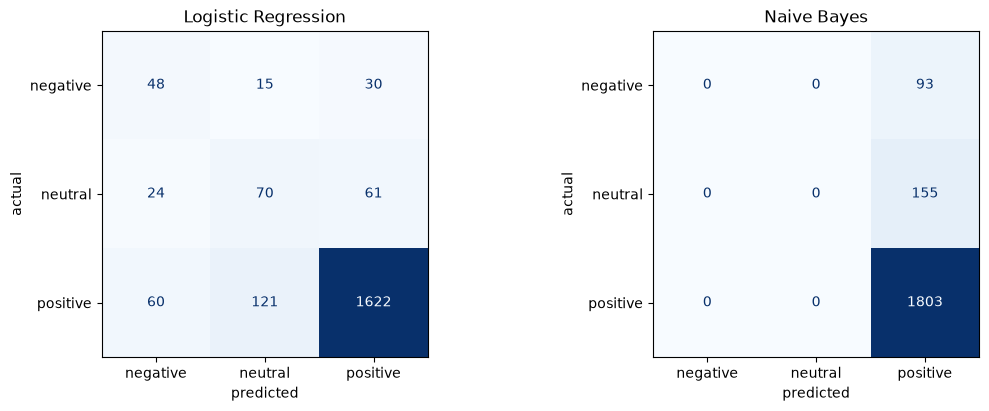

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
labels_order = ["negative", "neutral", "positive"]

for ax, (name, y_pred) in zip(
    axes,
    [("Logistic Regression", y_pred_lr), ("Naive Bayes", y_pred_nb)],
):
    cm = confusion_matrix(y_test, y_pred, labels=labels_order)
    disp = ConfusionMatrixDisplay(cm, display_labels=labels_order)
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")

plt.savefig("../plots/confusion_matrices_baselines.png", dpi=150)
plt.show()

In [18]:
mask = y_test != y_pred_lr
print(f"{mask.sum()} of {len(y_test)} test reviews misclassified by Logistic Regression\n")

errors = pd.DataFrame({
    "true": y_test[mask],
    "pred": pd.Series(y_pred_lr, index=y_test.index)[mask],
    "text": X_test[mask],
})

for _, row in errors.head(3).iterrows():
    print(f"TRUE: {row['true']} | PRED: {row['pred']}")
    print(row["text"][:150])
    print("-" * 80)

311 of 2051 test reviews misclassified by Logistic Regression

TRUE: positive | PRED: neutral
tuner clip easily instrument show pitch quickly accurately screen bright battery last long time actually dims display battery dying last like month ba
--------------------------------------------------------------------------------
TRUE: positive | PRED: neutral
work well standard clutch drop clutch iffy top part spin around hit lever grab move back hit
--------------------------------------------------------------------------------
TRUE: neutral | PRED: negative
not greatest cord ever used not worst either would prefer fender tweed cable one make recommendation
--------------------------------------------------------------------------------


In [19]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [20]:
baseline_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=20000)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
])

fold_scores = cross_val_score(
    baseline_pipe, X_train, y_train,
    cv=cv, scoring="f1_macro", n_jobs=-1,
)

print("per-fold macro F1:", fold_scores.round(3))
print(f"mean: {fold_scores.mean():.3f}  |  std: {fold_scores.std():.3f}")

per-fold macro F1: [0.525 0.501 0.515 0.496 0.523]
mean: 0.512  |  std: 0.012


In [21]:
lr_grid = GridSearchCV(
    Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=20000)),
        ("clf", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    param_grid={
        "tfidf__min_df": [3, 5],
        "clf__C": [0.5, 1, 3],                 # inverse regularization strength
        "clf__class_weight": [None, "balanced"],  # was balancing actually worth it?
    },
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
)

start = time.time()
lr_grid.fit(X_train, y_train)
print(f"\ngrid search took {time.time() - start:.0f}s")
print("best params :", lr_grid.best_params_)
print("best macro F1:", round(lr_grid.best_score_, 3))

Fitting 5 folds for each of 12 candidates, totalling 60 fits

grid search took 26s
best params : {'clf__C': 1, 'clf__class_weight': 'balanced', 'tfidf__min_df': 3}
best macro F1: 0.512


In [22]:
nb_grid = GridSearchCV(
    Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=20000)),
        ("clf", MultinomialNB()),
    ]),
    param_grid={
        "tfidf__min_df": [3, 5],
        "clf__alpha": [0.1, 0.5, 1.0],       # smoothing strength
        "clf__fit_prior": [True, False],     # learn class priors from data or not
    },
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
)

nb_grid.fit(X_train, y_train)
print("best params :", nb_grid.best_params_)
print("best macro F1:", round(nb_grid.best_score_, 3))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
best params : {'clf__alpha': 0.1, 'clf__fit_prior': False, 'tfidf__min_df': 5}
best macro F1: 0.503


In [23]:
lr_results = pd.DataFrame(lr_grid.cv_results_)

(lr_results[[
    "mean_test_score", "std_test_score",
    "param_clf__C", "param_clf__class_weight", "param_tfidf__min_df",
]]
   .sort_values("mean_test_score", ascending=False)
   .head(5)
   .reset_index(drop=True)
   .round(3))

,mean_test_score,std_test_score,param_clf__C,param_clf__class_weight,param_tfidf__min_df
0,0.512,0.012,1.0,balanced,3
1,0.508,0.018,3.0,balanced,3
2,0.507,0.014,0.5,balanced,3
3,0.506,0.018,3.0,balanced,5
4,0.504,0.015,1.0,balanced,5


In [24]:
print("LR best CV macro F1:", round(lr_grid.best_score_, 3))
print("NB best CV macro F1:", round(nb_grid.best_score_, 3))
print()

if lr_grid.best_score_ >= nb_grid.best_score_:
    best_model = lr_grid.best_estimator_
    print("WINNER: Logistic Regression")
else:
    best_model = nb_grid.best_estimator_
    print("WINNER: Naive Bayes")

print("test set remains untouched until Phase 10")

LR best CV macro F1: 0.512
NB best CV macro F1: 0.503

WINNER: Logistic Regression
test set remains untouched until Phase 10


In [31]:
y_pred_final = best_model.predict(X_test)

print("FINAL MODEL - tuned Logistic Regression pipeline")
print("accuracy :", round(accuracy_score(y_test, y_pred_final), 3))
print("macro F1 :", round(f1_score(y_test, y_pred_final, average="macro"), 3))
print()
print(classification_report(y_test, y_pred_final))

FINAL MODEL - tuned Logistic Regression pipeline
accuracy : 0.848
macro F1 : 0.579

              precision    recall  f1-score   support

    negative       0.36      0.52      0.43        93
     neutral       0.34      0.45      0.39       155
    positive       0.95      0.90      0.92      1803

    accuracy                           0.85      2051
   macro avg       0.55      0.62      0.58      2051
weighted avg       0.87      0.85      0.86      2051



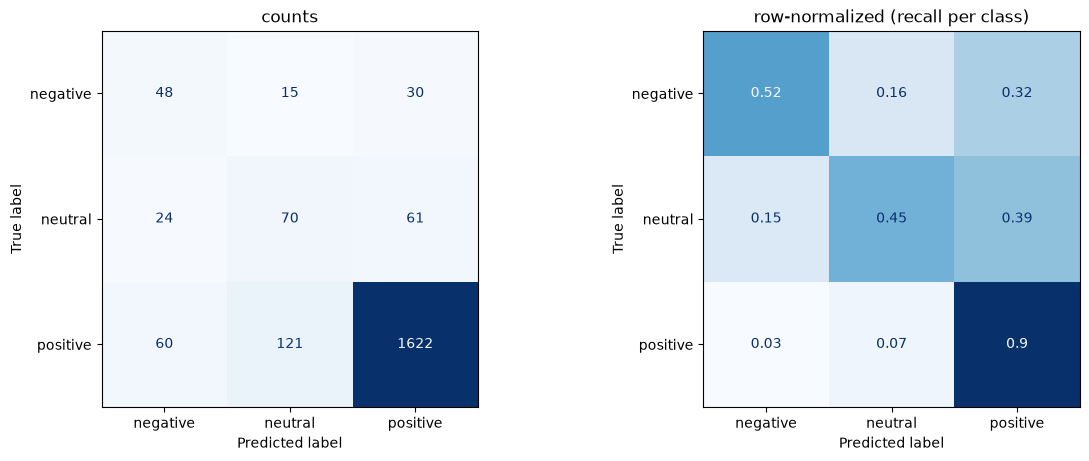

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
labels_order = ["negative", "neutral", "positive"]

cm      = confusion_matrix(y_test, y_pred_final, labels=labels_order)
cm_norm = confusion_matrix(y_test, y_pred_final, labels=labels_order, normalize="true")

ConfusionMatrixDisplay(cm, display_labels=labels_order).plot(ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("counts")

ConfusionMatrixDisplay(cm_norm.round(2), display_labels=labels_order).plot(ax=axes[1], colorbar=False, cmap="Blues")
axes[1].set_title("row-normalized (recall per class)")

plt.savefig("../plots/final_confusion_matrix.png", dpi=150)
plt.show()

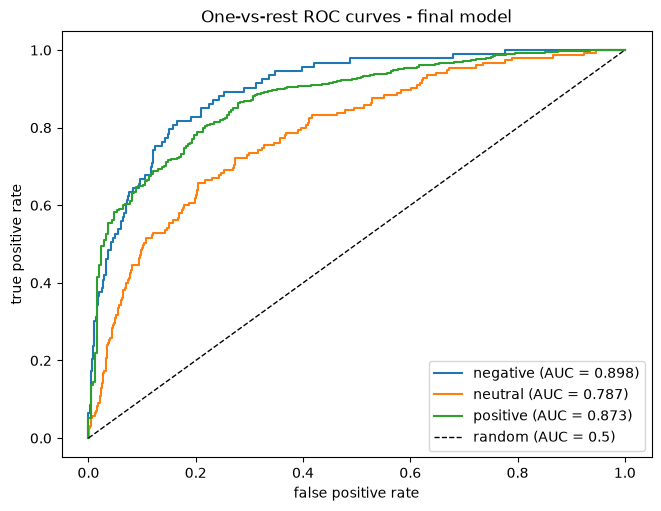

In [27]:
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import label_binarize

classes = ["negative", "neutral", "positive"]   # matches clf.classes_ order
y_test_bin = label_binarize(y_test, classes=classes)
proba = best_model.predict_proba(X_test)

fig, ax = plt.subplots(figsize=(6.5, 5), constrained_layout=True)

for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], proba[:, i])
    auc = roc_auc_score(y_test_bin[:, i], proba[:, i])
    ax.plot(fpr, tpr, label=f"{cls} (AUC = {auc:.3f})")

ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="random (AUC = 0.5)")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("One-vs-rest ROC curves - final model")
ax.legend(loc="lower right")

plt.savefig("../plots/roc_curves_final.png", dpi=150)
plt.show()

In [28]:
tfidf_step = best_model.named_steps["tfidf"]
clf_step   = best_model.named_steps["clf"]

feature_names = tfidf_step.get_feature_names_out()
coefs         = clf_step.coef_          # one weight vector per class

for row, cls in enumerate(clf_step.classes_):
    top_idx = coefs[row].argsort()[-10:][::-1]
    print(f"top words pushing toward '{cls}':")
    print("  ", ", ".join(feature_names[i] for i in top_idx))
    print()

top words pushing toward 'negative':
   not, broke, something, defective, returned, garbage, not recommend, junk, description, way

top words pushing toward 'neutral':
   ok, little, around, overall, feel, thin, however, use, quickly, pick

top words pushing toward 'positive':
   great, perfect, love, well, easy, best, perfectly, beat, work great, highly



In [29]:
mask = y_test != y_pred_final
print(f"{mask.sum()} of {len(y_test)} test reviews misclassified\n")

error_pairs = (pd.DataFrame({
    "true": y_test[mask],
    "pred": pd.Series(y_pred_final, index=y_test.index)[mask],
}).value_counts().rename("count"))
print(error_pairs)
print()

errors = pd.DataFrame({
    "true": y_test[mask],
    "pred": pd.Series(y_pred_final, index=y_test.index)[mask],
    "text": X_test[mask],
    "p_neg": proba[mask][:, 0],
    "p_neu": proba[mask][:, 1],
    "p_pos": proba[mask][:, 2],
})

print("=== THE COSTLY MISS: true negative -> predicted positive ===")
for _, row in errors[(errors["true"] == "negative") & (errors["pred"] == "positive")].head(3).iterrows():
    print(f"[neg {row['p_neg']:.2f} | neu {row['p_neu']:.2f} | pos {row['p_pos']:.2f}]")
    print(row["text"][:150])
    print("-" * 80)

print("\n=== true neutral -> predicted negative (the hedging problem) ===")
for _, row in errors[(errors["true"] == "neutral") & (errors["pred"] == "negative")].head(2).iterrows():
    print(f"[neg {row['p_neg']:.2f} | neu {row['p_neu']:.2f} | pos {row['p_pos']:.2f}]")
    print(row["text"][:150])
    print("-" * 80)

311 of 2051 test reviews misclassified

true      pred    
positive  neutral     121
neutral   positive     61
positive  negative     60
negative  positive     30
neutral   negative     24
negative  neutral      15
Name: count, dtype: int64

=== THE COSTLY MISS: true negative -> predicted positive ===
[neg 0.32 | neu 0.33 | pos 0.35]
bought add layer sound blue tune record note not bend easily think cheat big boy harp youll dissapointed quickly little toy compared dollar harp feel 
--------------------------------------------------------------------------------
[neg 0.35 | neu 0.23 | pos 0.42]
lasted yr lot cheaper cable get use abuse one outlasted
--------------------------------------------------------------------------------
[neg 0.33 | neu 0.08 | pos 0.59]
sound nice unreliable bx deluxe pair yamaha n event currently working without problem year use year ago purchased set regular bx lasted year faulty ca
------------------------------------------------------------------------------

In [30]:
final_table = pd.DataFrame({
    "baseline LR (Phase 8)": scores(y_test, y_pred_lr),
    "final tuned LR":        scores(y_test, y_pred_final),
}).round(3)

print(final_table)
print()
print("Phase 8 single-split macro F1 :", 0.579, " <- lucky draw")
print("Phase 9 CV estimate           :", round(lr_grid.best_score_, 3), " <- honest center")
print("Phase 10 FINAL test macro F1  :", round(final_table.loc["macro_f1", "final tuned LR"], 3))

             baseline LR (Phase 8)  final tuned LR
accuracy                     0.848           0.848
macro_f1                     0.579           0.579
weighted_f1                  0.860           0.860
negative_f1                  0.427           0.427
neutral_f1                   0.388           0.388
positive_f1                  0.923           0.923

Phase 8 single-split macro F1 : 0.579  <- lucky draw
Phase 9 CV estimate           : 0.512  <- honest center
Phase 10 FINAL test macro F1  : 0.579


In [32]:
import os
import joblib

model_path = "../models/sentiment_pipeline.joblib"
joblib.dump(best_model, model_path)

print("saved:", model_path)
print(f"size: {os.path.getsize(model_path) / 1e6:.1f} MB")

saved: ../models/sentiment_pipeline.joblib
size: 1.3 MB


In [35]:
import sys
sys.path.append("..")

from app.preprocess import preprocess_text

loaded = joblib.load("../models/sentiment_pipeline.joblib")

# training/serving skew check: the app's preprocessing must match
# the notebook's preprocessing on the same raw text
sample = df["reviewText"].sample(500, random_state=42)
same = (sample.apply(preprocess_text) == df.loc[sample.index, "clean_review"]).all()

print("module preprocessing identical to training:", bool(same))

module preprocessing identical to training: True


In [36]:
demo_reviews = [
    "This pedal is amazing! Best purchase I've made all year, sounds incredible.",
    "Total waste of money. It doesn't work at all and broke after two days.",
    "It's an okay cable, does the job but nothing special.",
    "The tuner works sometimes, but the display is hard to read in daylight.",
]

cleaned = [preprocess_text(r) for r in demo_reviews]
preds   = loaded.predict(cleaned)
probs   = loaded.predict_proba(cleaned).round(3)

for review, pred, p in zip(demo_reviews, preds, probs):
    print(f"PREDICTED: {pred}   [neg {p[0]} | neu {p[1]} | pos {p[2]}]")
    print("   ", review[:80])
    print()

PREDICTED: positive   [neg 0.041 | neu 0.045 | pos 0.915]
    This pedal is amazing! Best purchase I've made all year, sounds incredible.

PREDICTED: negative   [neg 0.879 | neu 0.108 | pos 0.013]
    Total waste of money. It doesn't work at all and broke after two days.

PREDICTED: neutral   [neg 0.046 | neu 0.879 | pos 0.075]
    It's an okay cable, does the job but nothing special.

PREDICTED: positive   [neg 0.231 | neu 0.328 | pos 0.44]
    The tuner works sometimes, but the display is hard to read in daylight.



In [37]:
import os
print(sorted(os.listdir("../plots")))

['confusion_matrices_baselines.png', 'final_confusion_matrix.png', 'length_by_sentiment.png', 'rating_distribution.png', 'review_length_histogram.png', 'reviews_per_year.png', 'roc_curves_final.png', 'sentiment_distribution.png', 'top_bigrams_by_sentiment.png', 'top_words_by_sentiment.png', 'wordclouds_by_sentiment.png']
